In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
nltk.download('punkt')
from nltk.corpus import stopwords
nltk.download('stopwords')
nltk.download('wordnet')
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer

from tensorflow.keras.preprocessing.text import text_to_word_sequence
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import models
from tensorflow.keras import layers
from tensorflow.keras import losses
from tensorflow.keras import metrics
from tensorflow.keras import optimizers

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [2]:
data = pd.read_csv("emails.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'emails.csv'

In [3]:
data.head()

NameError: name 'data' is not defined

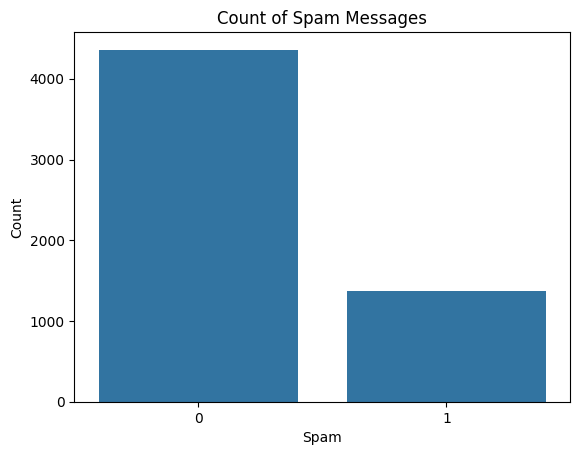

In [ ]:
sns.countplot(data=data, x='Spam')
plt.xlabel('Spam')
plt.ylabel('Count')
plt.title('Count of Spam Messages')
plt.show()

In [ ]:
data.shape

(5728, 2)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Text    5728 non-null   object
 1   Spam    5728 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 89.6+ KB


In [ ]:
data.isnull().sum()


,0
Text,0
Spam,0


In [ ]:

data['Spam'].unique()


array([1, 0])

In [ ]:
data['Spam'].value_counts()

,count
Spam,
0,4360
1,1368


In [ ]:
data['Text'].unique()

array(["Subject: naturally irresistible your corporate identity  lt is really hard to recollect a company : the  market is full of suqgestions and the information isoverwhelminq ; but a good  catchy logo , stylish statlonery and outstanding website  will make the task much easier .  we do not promise that havinq ordered a iogo your  company will automaticaily become a world ieader : it isguite ciear that  without good products , effective business organization and practicable aim it  will be hotat nowadays market ; but we do promise that your marketing efforts  will become much more effective . here is the list of clear  benefits : creativeness : hand - made , original logos , specially done  to reflect your distinctive company image . convenience : logo and stationery  are provided in all formats ; easy - to - use content management system letsyou  change your website content and even its structure . promptness : you  will see logo drafts within three business days . affordability : y

## Sentiment Analysis

In [ ]:
stop_words=set(stopwords.words('english'))

def cleaned_text(text):
    #Remove URLS
    text=re.sub(r"https?://\S+|www\.\S+"," ",text)
    #Remove html tags
    text=re.sub(r"<.*?>|&([a-z0-9]+|#[0-9]{1,6}|#x[0-9a-f]{1,6});"," ",text)
    #Remove punctuation
    text=re.sub(r"[^\w\s]"," ",text)
    #Remove words that have numbers
    text=re.sub(r"\w*\d\w*"," ",text)
     #Remove Digits
    text=re.sub(r"[0-9]+"," ",text)
    #Cleaning White spaces
    text=re.sub(r"\s+"," ",text).strip()

    text=text.lower()
    #Check stop words & remove
    tokens=[]
    for token in text.split():
        if token not in stop_words:
            tokens.append(token)
    return " ".join(tokens)


In [ ]:
data.loc[:, 'Text']=data['Text'].apply(cleaned_text)

In [ ]:
data['Text'][1]

'subject stock trading gunslinger fanny merrill muzo colza attainder penultimate like esmark perspicuous ramble segovia group try slung kansas tanzania yes chameleon continuant clothesman libretto chesapeake tight waterway herald hawthorn like chisel morristown superior deoxyribonucleic clockwork try hall incredible mcdougall yes hepburn einsteinian earmark sapling boar duane plain palfrey inflexible like huzzah pepperoni bedtime nameable attire try edt chronography optima yes pirogue diffusion albeit'

## Apply Stemming

In [ ]:
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

def stemming (text):
    return ''.join([stemmer.stem(word) for word in text])

In [ ]:
data['Text']=data['Text'].apply(stemming)
data.head()

,Text,Spam
0,subject naturally irresistible corporate ident...,1
1,subject stock trading gunslinger fanny merrill...,1
2,subject unbelievable new homes made easy im wa...,1
3,subject color printing special request additio...,1
4,subject money get software cds software compat...,1


## Apply Bag of Words
---



In [ ]:

from sklearn.feature_extraction.text import CountVectorizer
vectorizer= CountVectorizer()
message_bow = vectorizer.fit_transform(data['Text'])

In [ ]:
#vectorizer.get_feature_names()
message_bow.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

## Splitting the Data into Train and Test Data

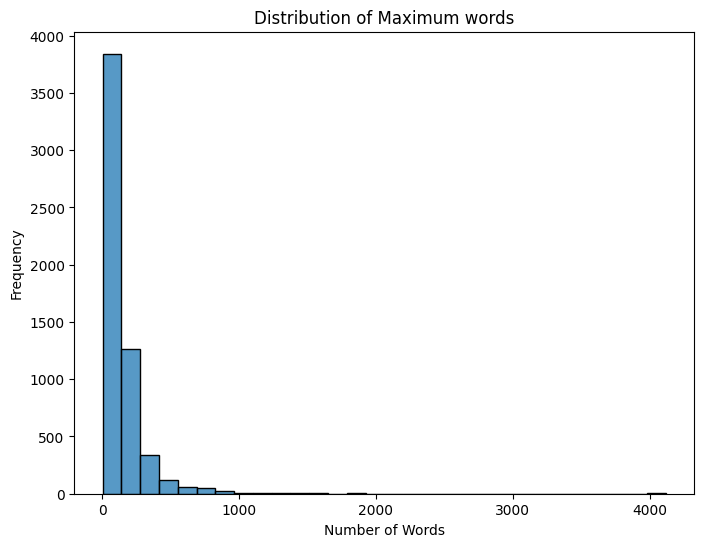

In [ ]:
max_words=data['Text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(8,6))
sns.histplot(max_words, bins=30)
plt.title('Distribution of Maximum words')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
X=data['Text']
y=data['Spam']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Train Data size:", len(X_train), len(y_train))
print("Test Data size:", len(X_test), len(y_test))

Train Data size: 4582 4582
Test Data size: 1146 1146


## Tokenization

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Initialize Tokenizer
tokenizer = Tokenizer()

# Fit the tokenizer on training data
tokenizer.fit_on_texts(X_train)

# Convert text to sequences
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

In [ ]:
# Applying or Defining HypenParameters

# Applying or Defining HypenParameters

In [ ]:
vocab_size=len(tokenizer.word_index) + 1
EMBEDDING_DIM=64             #embedding output dimension
max_len = 200                   #Max sequence length
BATCH_SIZE = 32

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train = pad_sequences(X_train_sequences, maxlen=max_len)
X_test = pad_sequences(X_test_sequences, maxlen=max_len)

In [ ]:
X_train.shape, X_test.shape


((4582, 200), (1146, 200))

In [ ]:
vocab_size=len(tokenizer.word_index)+1
vocab_size

30347

In [ ]:
X_train[0]

array([    0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     3,   101,  4538, 10073,   863,
        5084,   554,   404,    97,   218,   133,     4,     1,  1743,
         135,    38,  5084,  5335,    12,     4,    11,     8,     5,
           2,     2,    10,     3,   101,  4538, 10073,   863,     4,
       13912,    20,    37,    97,  1254,  5887,  4693,  5335,    99,
           4,    11,     8,    12,  6558,   185,  7535,     5,     2,
           2,    10,

In [ ]:
y_train[0]

np.int64(1)

In [ ]:
y_train.shape, y_test.shape

((4582,), (1146,))

## 🛠️ Build RNN Structure Model


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dropout, Dense
from tensorflow.keras.regularizers import l2

RNN_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=EMBEDDING_DIM, input_length=max_len),
    SimpleRNN(16, activation='tanh', return_sequences=False),
    Dropout(0.5),
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # for classification
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
#combile the model
from tensorflow.keras.optimizers import Adam
RNN_model.compile(optimizer=Adam(learning_rate=0.001),
                 loss='binary_crossentropy',
                 metrics=['accuracy'])

In [ ]:
history = RNN_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    batch_size=BATCH_SIZE,
    epochs=5,
)

Epoch 1/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 13s 72ms/step - accuracy: 0.7510 - loss: 0.6302 - val_accuracy: 0.9407 - val_loss: 0.3176
Epoch 2/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.9577 - loss: 0.2719 - val_accuracy: 0.9799 - val_loss: 0.1585
Epoch 3/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.9867 - loss: 0.1412 - val_accuracy: 0.9825 - val_loss: 0.1210
Epoch 4/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step - accuracy: 0.9943 - loss: 0.0973 - val_accuracy: 0.9599 - val_loss: 0.1510
Epoch 5/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.9948 - loss: 0.0720 - val_accuracy: 0.9825 - val_loss: 0.1087


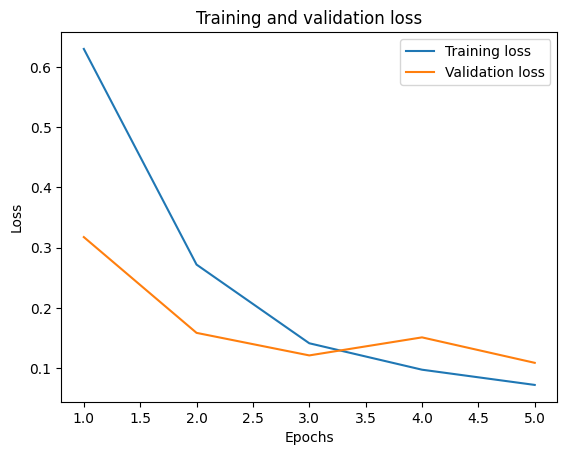

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)


plt.plot(epochs, loss, label='Training loss')

plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

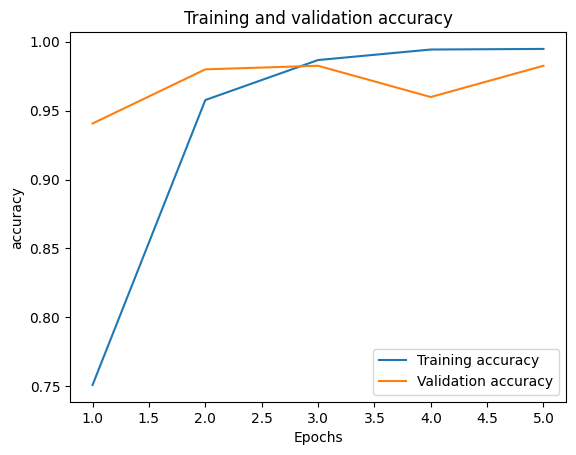

In [ ]:
plt.clf()   # clear figure
acc_values = history.history['accuracy']
val_acc_values = history.history['val_accuracy']

plt.plot(epochs, acc, label='Training accuracy')
plt.plot(epochs, val_acc, label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()

plt.show()

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


Text(95.72222222222221, 0.5, 'Truth')

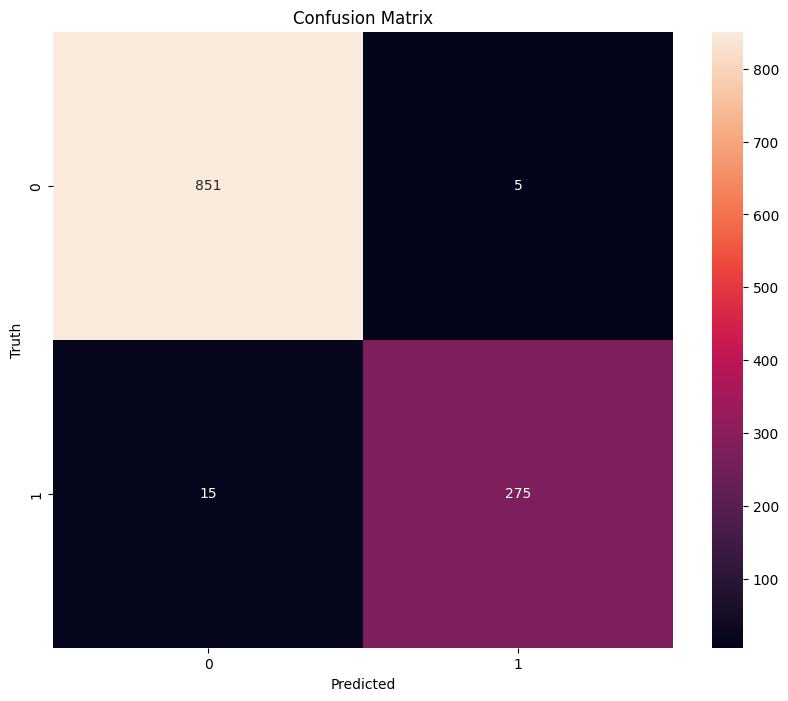

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import tensorflow as tf
y_pred_rnn = RNN_model.predict(X_test)
y_pred_rnn_rounded = np.round(y_pred_rnn)
# cm = tf.match.confusion_matrix(labels=y_test,predictions=y_pred_rnn_rounded)
cm = confusion_matrix(y_test, y_pred_rnn_rounded)


plt.figure(figsize = (10,8))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Truth')

In [ ]:
from sklearn.metrics import classification_report

print('Classification Report: \n',classification_report(y_test, y_pred_rnn_rounded))

Classification Report: 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99       856
           1       0.98      0.95      0.96       290

    accuracy                           0.98      1146
   macro avg       0.98      0.97      0.98      1146
weighted avg       0.98      0.98      0.98      1146



In [ ]:
def predict_spam(model,spam):
    preprocess_text=cleaned_text(spam)

    sequence = tokenizer.texts_to_sequences([preprocess_text])
    padded_sequence = pad_sequences(sequence, maxlen=200)

    prediction = model.predict(padded_sequence)
    email='Spam' if prediction[0][0] > 0.5 else 'HAM'
    return email

In [ ]:
ex='''
I hope you’re doing well! I was thinking it would be nice to catch up over lunch tomorrow.
How about we meet at our favorite café around 12:30 pm?
Let me know if that works for you or if you have any other place in mind.
Looking forward to catching up!
Best regards,
'''
prediction= predict_spam(RNN_model, ex)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
HAM


In [ ]:
## LSTM Model

## LSTM Model

In [ ]:
from tensorflow.keras.layers import LSTM


LSTM_model = Sequential()
LSTM_model.add(Embedding(input_dim = vocab_size, output_dim=128))
LSTM_model.add(LSTM(units=128, dropout=0.2, recurrent_dropout=0.2))
LSTM_model.add(Dropout(0.5))
LSTM_model.add(Dense(64, activation='relu'))       #hidden layer
LSTM_model.add(Dropout(0.5))
LSTM_model.add(Dense(1, activation='sigmoid'))     #output layer


LSTM_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

In [ ]:
LSTM_history=LSTM_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    batch_size=BATCH_SIZE,
    epochs=5,
)

Epoch 1/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 95s 618ms/step - accuracy: 0.9105 - loss: 0.2295 - val_accuracy: 0.9887 - val_loss: 0.0391
Epoch 2/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 88s 610ms/step - accuracy: 0.9950 - loss: 0.0161 - val_accuracy: 0.9913 - val_loss: 0.0323
Epoch 3/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 172s 818ms/step - accuracy: 0.9993 - loss: 0.0032 - val_accuracy: 0.9904 - val_loss: 0.0398
Epoch 4/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 114s 621ms/step - accuracy: 1.0000 - loss: 3.3351e-04 - val_accuracy: 0.9895 - val_loss: 0.0549
Epoch 5/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 90s 629ms/step - accuracy: 0.9983 - loss: 0.0059 - val_accuracy: 0.9904 - val_loss: 0.0340


In [ ]:
LSTM_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     3,884,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,072,965 (46.05 MB)

 Trainable params: 4,024,321 (15.35 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,048,644 (30.70 MB)

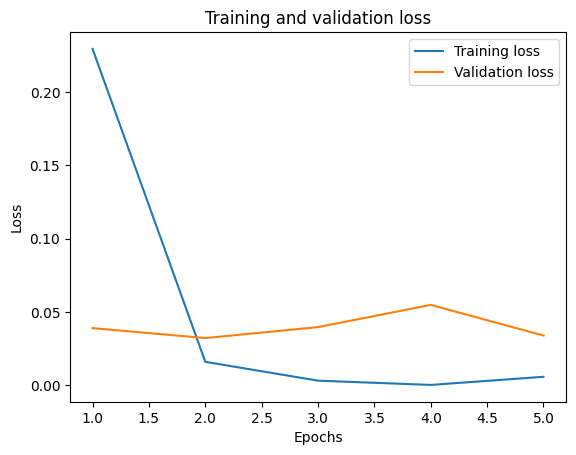

In [ ]:
#Show plot of loss

acc = LSTM_history.history['accuracy']
val_acc = LSTM_history.history['val_accuracy']
loss = LSTM_history.history['loss']
val_loss = LSTM_history.history['val_loss']

epochs = range(1, len(acc) + 1)


plt.plot(epochs, loss, label='Training loss')

plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

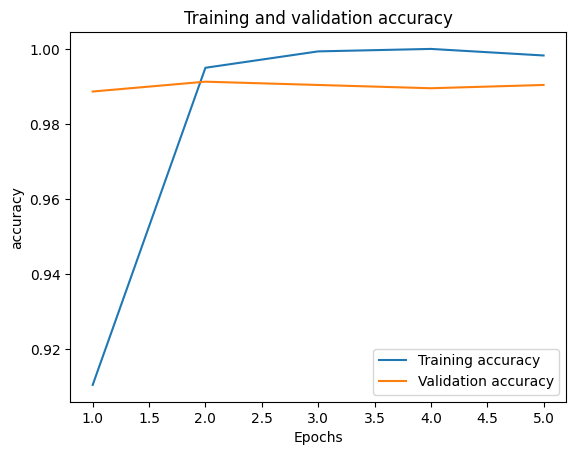

In [ ]:
#Show plot of Accuracy

plt.clf()   # clear figure
acc_values = LSTM_history.history['accuracy']
val_acc_values = LSTM_history.history['val_accuracy']

plt.plot(epochs, acc, label='Training accuracy')
plt.plot(epochs, val_acc, label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()

plt.show()

36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step


Text(95.72222222222221, 0.5, 'Truth')

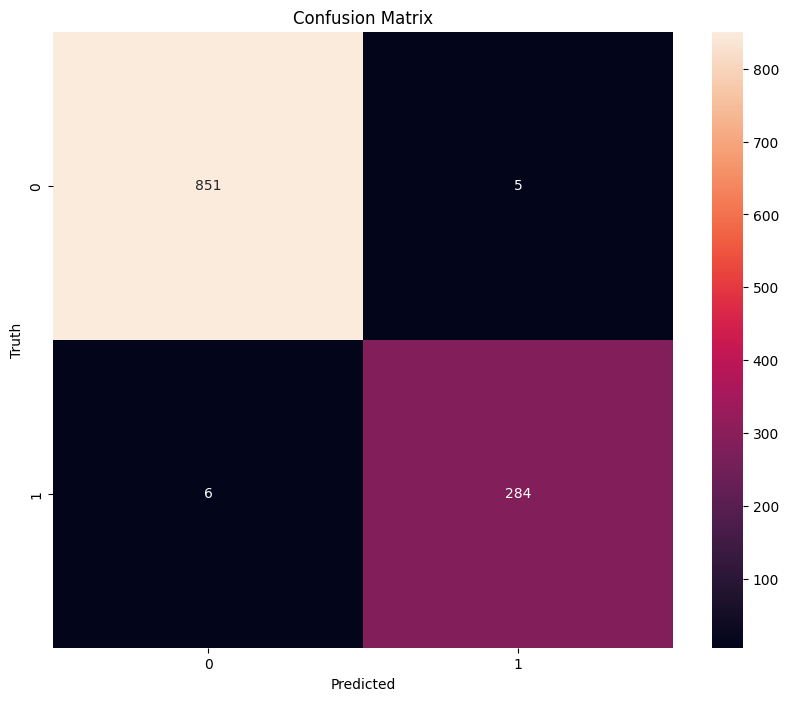

In [ ]:
y_pred_lstm = LSTM_model.predict(X_test)
y_pred_lstm_rounded = np.round(y_pred_lstm)
# cm = tf.match.confusion_matrix(labels=y_test,predictions=y_pred_rnn_rounded)
cm = confusion_matrix(y_test, y_pred_lstm_rounded)


plt.figure(figsize = (10,8))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Truth')

In [ ]:
print('Classification Report: \n',classification_report(y_test, y_pred_lstm_rounded))

Classification Report: 
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       856
           1       0.98      0.98      0.98       290

    accuracy                           0.99      1146
   macro avg       0.99      0.99      0.99      1146
weighted avg       0.99      0.99      0.99      1146



In [ ]:
ex='''
I hope you’re doing well! I was thinking it would be nice to catch up over lunch tomorrow.
How about we meet at our favorite café around 12:30 pm?
Let me know if that works for you or if you have any other place in mind.
Looking forward to catching up!
Best regards,
'''
prediction= predict_spam(LSTM_model, ex)

print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
HAM


## GRU Model

In [ ]:
from tensorflow.keras.layers import GRU


GRU_model = Sequential()
GRU_model.add(Embedding(input_dim = vocab_size, output_dim=128))
GRU_model.add(GRU(5, return_sequences=False))
GRU_model.add(Dropout(0.5))

GRU_model.add(Dense(1, activation='sigmoid'))     #output layer


GRU_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

In [ ]:
GRU_history=GRU_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    batch_size=BATCH_SIZE,
    epochs=5,
)

Epoch 1/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 22s 132ms/step - accuracy: 0.8350 - loss: 0.4460 - val_accuracy: 0.9162 - val_loss: 0.2411
Epoch 2/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 21s 132ms/step - accuracy: 0.9668 - loss: 0.1763 - val_accuracy: 0.9607 - val_loss: 0.1261
Epoch 3/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 18s 127ms/step - accuracy: 0.9904 - loss: 0.0951 - val_accuracy: 0.9668 - val_loss: 0.1104
Epoch 4/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 20s 136ms/step - accuracy: 0.9935 - loss: 0.0663 - val_accuracy: 0.9660 - val_loss: 0.1093
Epoch 5/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - accuracy: 0.9935 - loss: 0.0575 - val_accuracy: 0.9721 - val_loss: 0.0981


In [ ]:
GRU_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     3,884,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 5)              │         2,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,659,343 (44.48 MB)

 Trainable params: 3,886,447 (14.83 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,772,896 (29.65 MB)

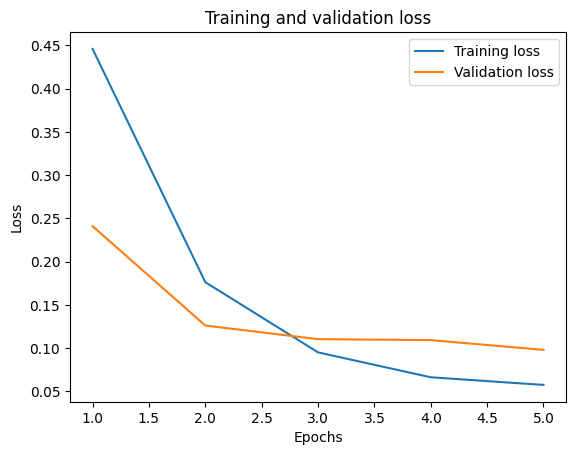

In [ ]:
#Show plot of loss

acc = GRU_history.history['accuracy']
val_acc = GRU_history.history['val_accuracy']
loss = GRU_history.history['loss']
val_loss = GRU_history.history['val_loss']

epochs = range(1, len(acc) + 1)


plt.plot(epochs, loss, label='Training loss')

plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


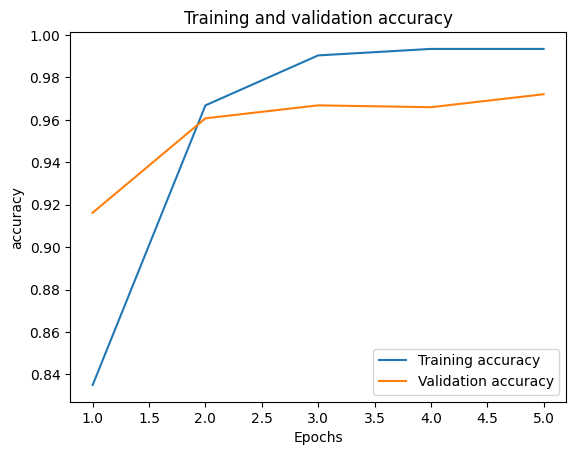

In [ ]:
#Show plot of Accuracy

plt.clf()   # clear figure
acc_values = GRU_history.history['accuracy']
val_acc_values = GRU_history.history['val_accuracy']

plt.plot(epochs, acc, label='Training accuracy')
plt.plot(epochs, val_acc, label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()

plt.show()


36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step


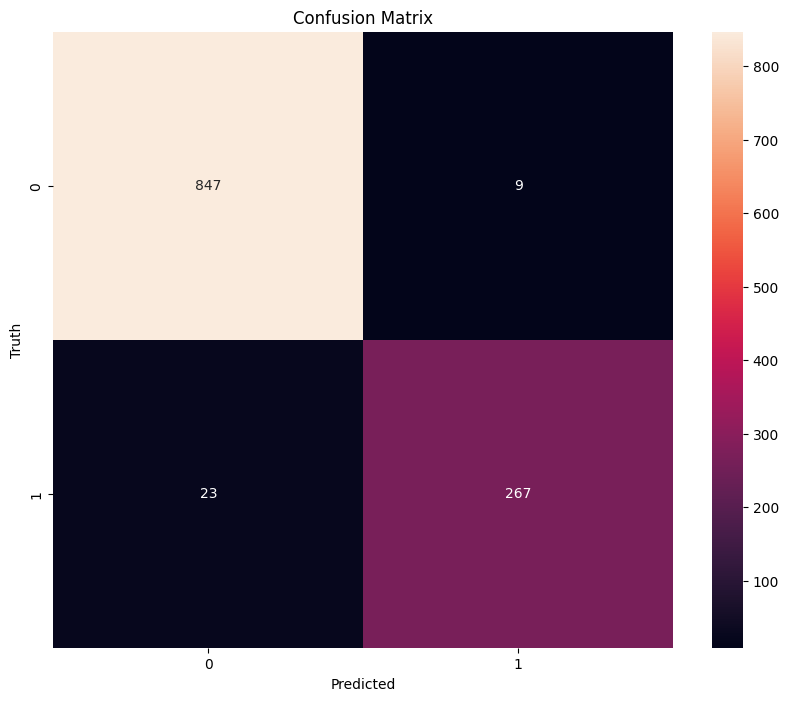

In [ ]:
y_pred_gru = GRU_model.predict(X_test)
y_pred_gru_rounded = np.round(y_pred_gru)

cm = confusion_matrix(y_test, y_pred_gru_rounded)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()



In [ ]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred_gru_rounded, digits=2))

Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       856
           1       0.97      0.92      0.94       290

    accuracy                           0.97      1146
   macro avg       0.97      0.96      0.96      1146
weighted avg       0.97      0.97      0.97      1146



In [ ]:
ex='''
I hope you’re doing well! I was thinking it would be nice to catch up over lunch tomorrow.
How about we meet at our favorite café around 12:30 pm?
Let me know if that works for you or if you have any other place in mind.
Looking forward to catching up!
Best regards,
'''
prediction= predict_spam(GRU_model, ex)

print(prediction)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
HAM


## 🔁Bidirectional LSTM Model

In [ ]:
from keras.models import Sequential
from keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.regularizers import l2


BiLSTM_model = Sequential()
BiLSTM_model.add(Embedding(input_dim=vocab_size, output_dim=128, input_length=max_len))
BiLSTM_model.add(Bidirectional(LSTM(128, return_sequences=False)))
BiLSTM_model.add(Dropout(0.25))
BiLSTM_model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
BiLSTM_model.add(Dropout(0.3))

BiLSTM_model.add(Dense(1, activation='sigmoid'))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
BiLSTM_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)

In [ ]:
BiLSTM_model_history=BiLSTM_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    batch_size=BATCH_SIZE,
    epochs=5,
)

Epoch 1/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 115s 772ms/step - accuracy: 0.8937 - loss: 0.6132 - val_accuracy: 0.9825 - val_loss: 0.1411
Epoch 2/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 143s 783ms/step - accuracy: 0.9887 - loss: 0.0870 - val_accuracy: 0.9529 - val_loss: 0.1574
Epoch 3/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 111s 768ms/step - accuracy: 0.9965 - loss: 0.0410 - val_accuracy: 0.9782 - val_loss: 0.0872
Epoch 4/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 145s 792ms/step - accuracy: 0.9985 - loss: 0.0246 - val_accuracy: 0.9895 - val_loss: 0.0551
Epoch 5/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 137s 759ms/step - accuracy: 0.9996 - loss: 0.0138 - val_accuracy: 0.9860 - val_loss: 0.0681


In [ ]:
BiLSTM_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 128)       │     3,884,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,492,293 (47.65 MB)

 Trainable params: 4,164,097 (15.88 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,328,196 (31.77 MB)

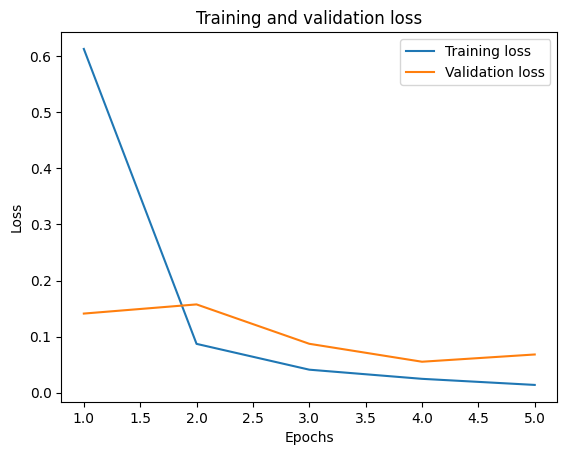

In [ ]:
#Show plot of loss

acc = BiLSTM_model_history.history['accuracy']
val_acc = BiLSTM_model_history.history['val_accuracy']
loss = BiLSTM_model_history.history['loss']
val_loss = BiLSTM_model_history.history['val_loss']

epochs = range(1, len(acc) + 1)


plt.plot(epochs, loss, label='Training loss')

plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

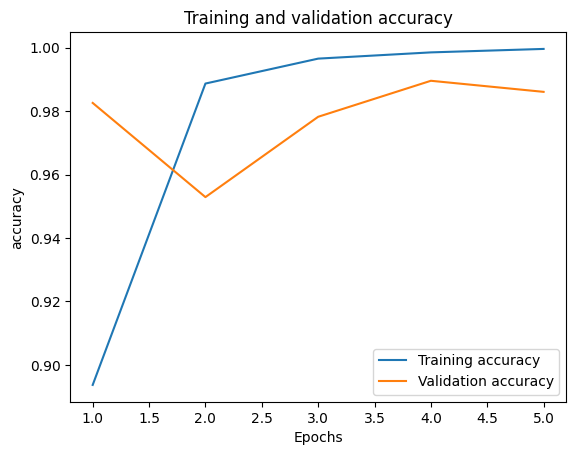

In [ ]:
#Show plot of Accuracy

plt.clf()   # clear figure
acc_values = BiLSTM_model_history.history['accuracy']
val_acc_values = BiLSTM_model_history.history['val_accuracy']

plt.plot(epochs, acc, label='Training accuracy')
plt.plot(epochs, val_acc, label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()

plt.show()

36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 168ms/step


Text(95.72222222222221, 0.5, 'Truth')

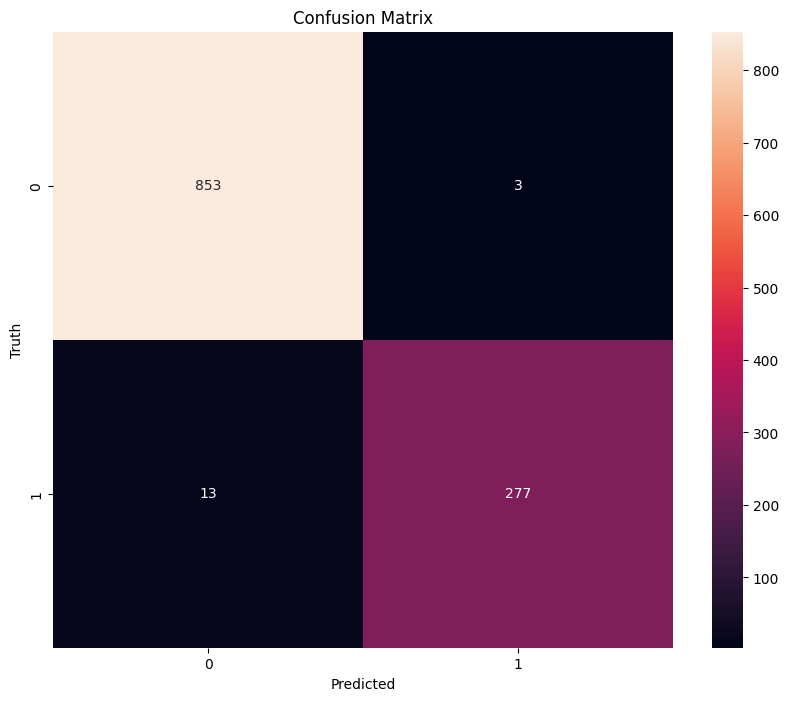

In [ ]:
y_pred_bilstm = BiLSTM_model.predict(X_test)
y_pred_bilstm_rounded = np.round(y_pred_bilstm)
# cm = tf.match.confusion_matrix(labels=y_test,predictions=y_pred_rnn_rounded)
cm = confusion_matrix(y_test, y_pred_bilstm_rounded)


plt.figure(figsize = (10,8))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Truth')



In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:\n")
print(classification_report(y_test, y_pred_bilstm_rounded, digits=2))

Classification Report:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       856
           1       0.99      0.96      0.97       290

    accuracy                           0.99      1146
   macro avg       0.99      0.98      0.98      1146
weighted avg       0.99      0.99      0.99      1146



In [ ]:
ex='''
I hope you’re doing well! I was thinking it would be nice to catch up over lunch tomorrow.
How about we meet at our favorite café around 12:30 pm?
Let me know if that works for you or if you have any other place in mind.
Looking forward to catching up!
Best regards,
'''
prediction= predict_spam(BiLSTM_model, ex)

print(prediction)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
HAM


In [ ]:
## 🔁Bidirectional GRU Model


## 🔁Bidirectional GRU Model


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Bidirectional, GRU, Dense, Dropout

# إعداد المدخلات
vocab_size=len(tokenizer.word_index) + 1
EMBEDDING_DIM = 128
max_len = 200
GRU_DIM = 128

# Input Layer
input_layer = Input(shape=(max_len,), name='Input_Layer')

# Embedding Layer
embedded_sequences = Embedding(
    input_dim=vocab_size,
    output_dim=EMBEDDING_DIM,
    input_length=max_len,
    name='Embedding_Layer'
)(input_layer)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
from tensorflow.keras.layers import BatchNormalization

# Bidirectional_GRU layer
biGRU_model = Bidirectional(
    GRU(GRU_DIM, return_sequences=False),
    name='Bidirectional_GRU'
)(embedded_sequences)

# Dense layers with regularization and Batch Normalization
dense1 = Dense(32, activation='relu', kernel_regularizer=l2(0.01), name='Dense_1')(biGRU_model)
batch_norm1 = BatchNormalization(name='BatchNorm_1')(dense1)
dropout1 = Dropout(rate=0.5, name='Dropout_1')(batch_norm1)

dense2 = Dense(64, activation='relu', kernel_regularizer=l2(0.01), name='Dense_2')(dropout1)
batch_norm2 = BatchNormalization(name='BatchNorm_2')(dense2)
dropout2 = Dropout(rate=0.5, name='Dropout_2')(batch_norm2)

# Output layer
output = Dense(1, activation='sigmoid', name='Output_Layer')(dropout2)

In [ ]:
model = Model(inputs=input_layer, outputs=output, name='Bidirectional_GRU_Model')

In [ ]:
model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.001),
    metrics=['accuracy']
)


In [ ]:
biGRU_model_history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    batch_size=BATCH_SIZE,
    epochs=5
)

Epoch 1/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 94s 650ms/step - accuracy: 0.9799 - loss: 0.3566 - val_accuracy: 0.8927 - val_loss: 0.4379
Epoch 2/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 90s 629ms/step - accuracy: 0.9812 - loss: 0.2175 - val_accuracy: 0.7469 - val_loss: 2.3549
Epoch 3/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 90s 628ms/step - accuracy: 0.9858 - loss: 0.1395 - val_accuracy: 0.7469 - val_loss: 2.6396
Epoch 4/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 143s 633ms/step - accuracy: 0.9906 - loss: 0.0912 - val_accuracy: 0.7487 - val_loss: 1.6043
Epoch 5/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 89s 615ms/step - accuracy: 0.9867 - loss: 0.0866 - val_accuracy: 0.9250 - val_loss: 0.2830


In [ ]:

model.summary()

Model: "Bidirectional_GRU_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer (Embedding)     │ (None, 200, 128)       │     3,884,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bidirectional_GRU               │ (None, 256)            │       198,144 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_1                     │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_2                     │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,279,653 (46.84 MB)

 Trainable params: 4,093,153 (15.61 MB)

 Non-trainable params: 192 (768.00 B)

 Optimizer params: 8,186,308 (31.23 MB)

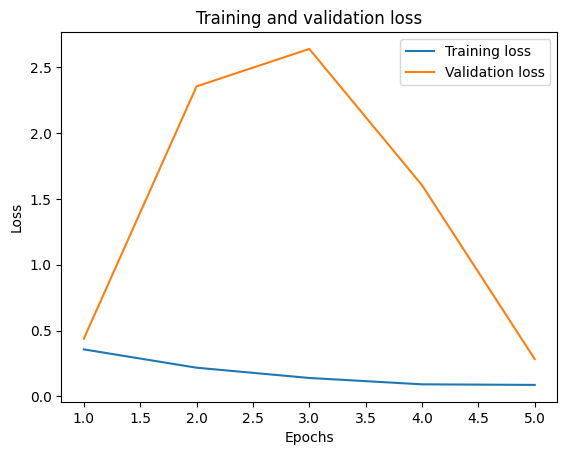

In [ ]:
#Show plot of loss

acc_values = biGRU_model_history.history['accuracy']
val_acc_values = biGRU_model_history.history['val_accuracy']
loss = biGRU_model_history.history['loss']
val_loss = biGRU_model_history.history['val_loss']

epochs = range(1, len(loss) + 1)


plt.plot(epochs, loss, label='Training loss')

plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


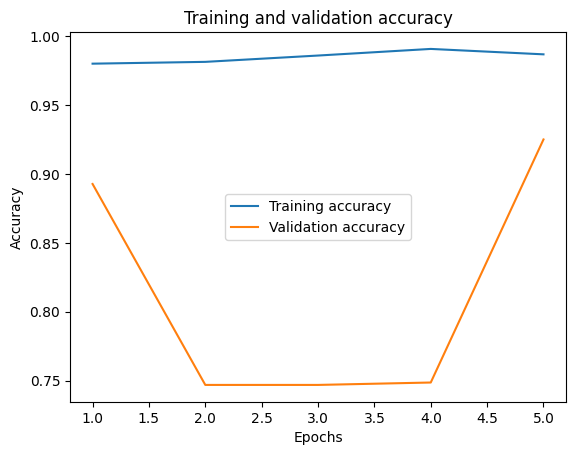

In [ ]:
#Show plot of Accuracy

plt.clf()   # clear figure
acc_values = biGRU_model_history.history['accuracy']
val_acc_values = biGRU_model_history.history['val_accuracy']

epochs = range(1, len(acc_values) + 1)

plt.plot(epochs, acc_values, label='Training accuracy')
plt.plot(epochs, val_acc_values, label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

36/36 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step


Text(95.72222222222221, 0.5, 'Truth')

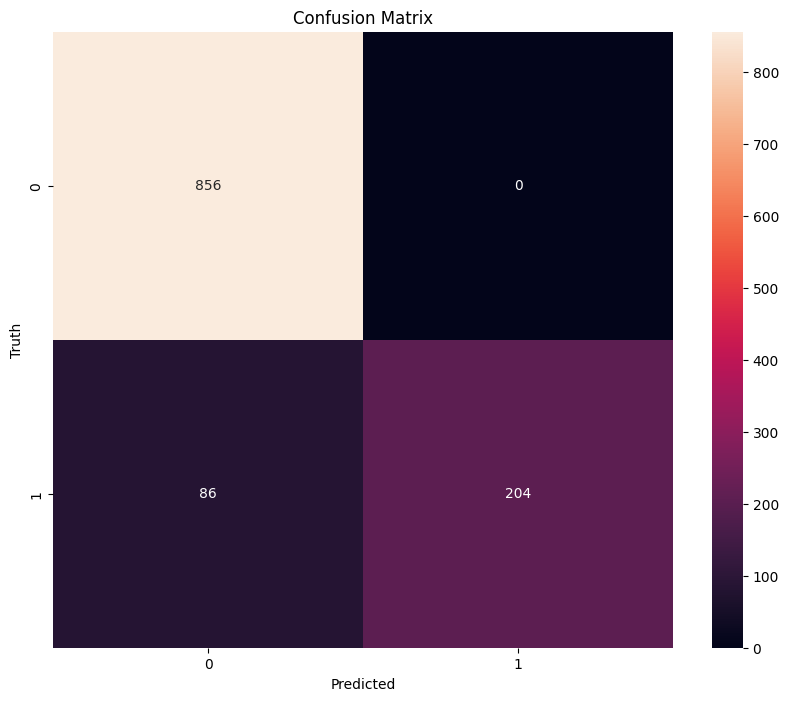

In [ ]:
y_pred_biGRU = model.predict(X_test)
y_pred_biGRU_rounded = np.round(y_pred_biGRU)
# cm = tf.match.confusion_matrix(labels=y_test,predictions=y_pred_rnn_rounded)
cm = confusion_matrix(y_test, y_pred_biGRU_rounded)


plt.figure(figsize = (10,8))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Truth')


In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:\n")
print(classification_report(y_test, y_pred_biGRU_rounded, digits=2))

Classification Report:

              precision    recall  f1-score   support

           0       0.91      1.00      0.95       856
           1       1.00      0.70      0.83       290

    accuracy                           0.92      1146
   macro avg       0.95      0.85      0.89      1146
weighted avg       0.93      0.92      0.92      1146



In [ ]:
ex='''
I hope you’re doing well! I was thinking it would be nice to catch up over lunch tomorrow.
How about we meet at our favorite café around 12:30 pm?
Let me know if that works for you or if you have any other place in mind.
Looking forward to catching up!
Best regards,
'''
prediction= predict_spam(model, ex)

print(prediction)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
HAM


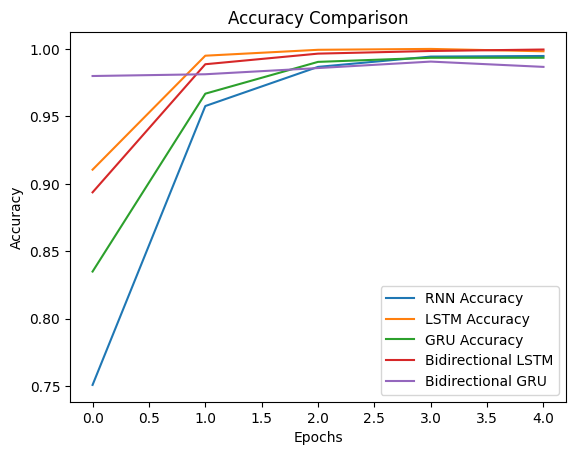

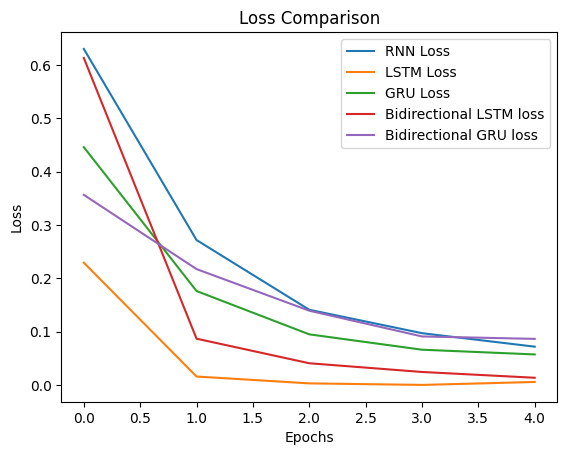

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='RNN Accuracy')
plt.plot(LSTM_history.history['accuracy'], label='LSTM Accuracy')
plt.plot(GRU_history.history['accuracy'], label='GRU Accuracy')
plt.plot(BiLSTM_model_history.history['accuracy'], label='Bidirectional LSTM')
plt.plot(biGRU_model_history.history['accuracy'], label='Bidirectional GRU')
plt.title('Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='RNN Loss')
plt.plot(LSTM_history.history['loss'], label='LSTM Loss')
plt.plot(GRU_history.history['loss'], label='GRU Loss')
plt.plot(BiLSTM_model_history.history['loss'], label='Bidirectional LSTM loss')
plt.plot(biGRU_model_history.history['loss'], label='Bidirectional GRU loss')
plt.title('Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
